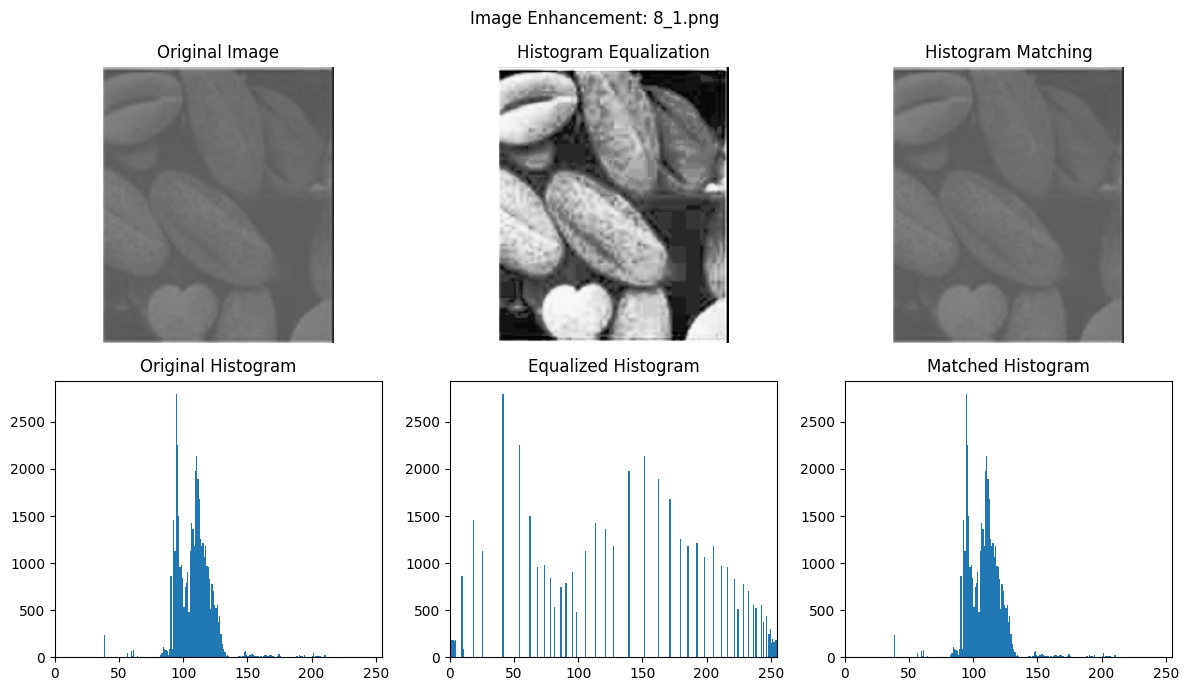

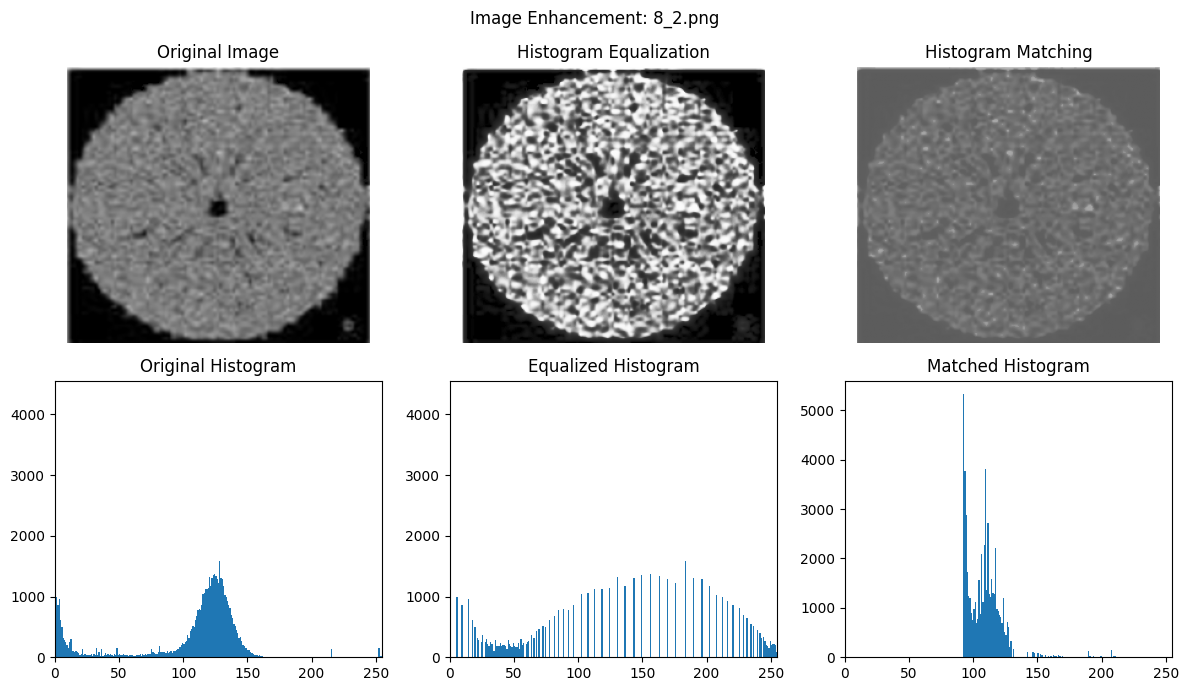

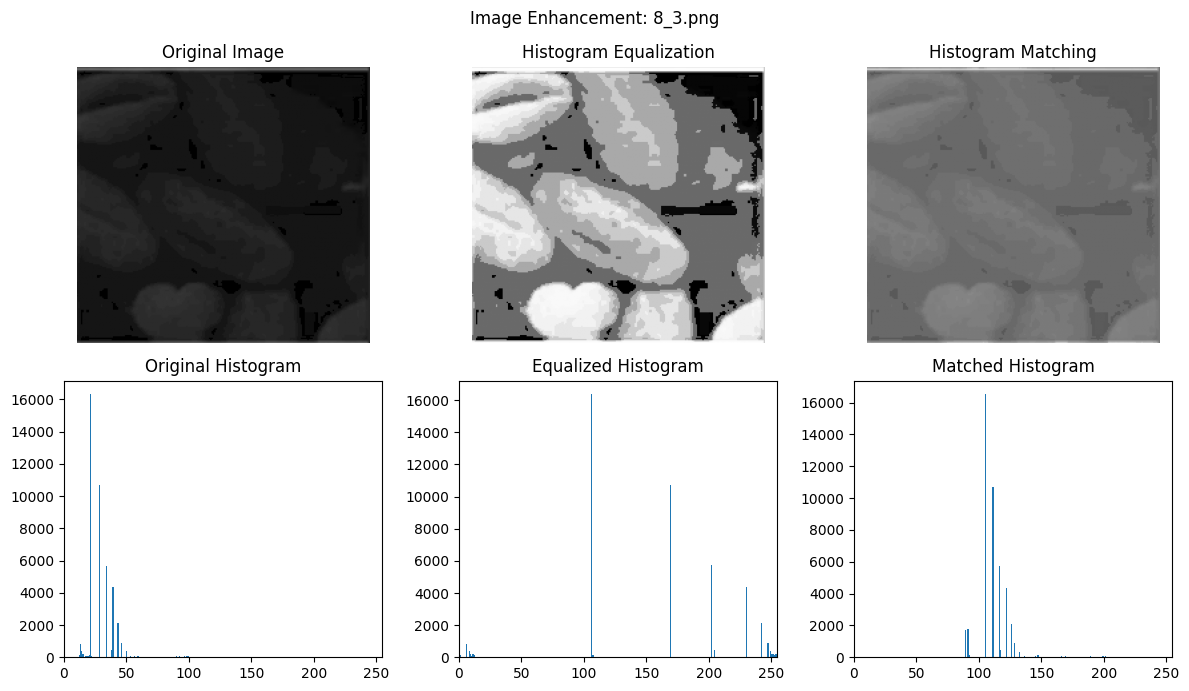

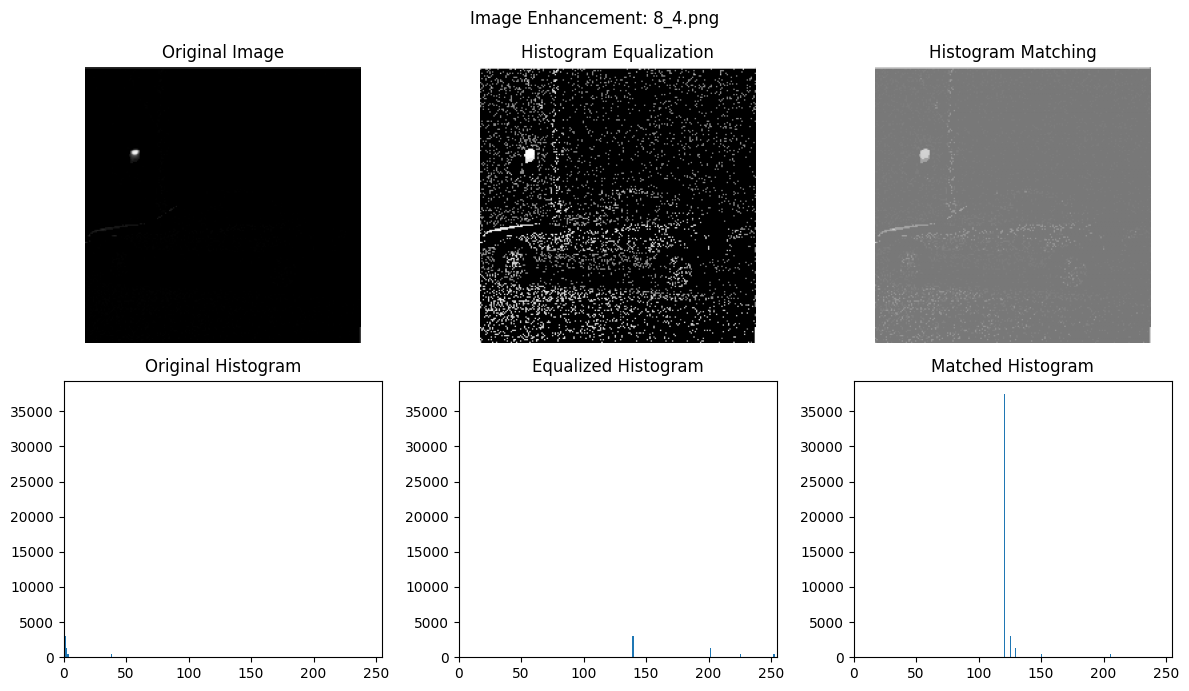

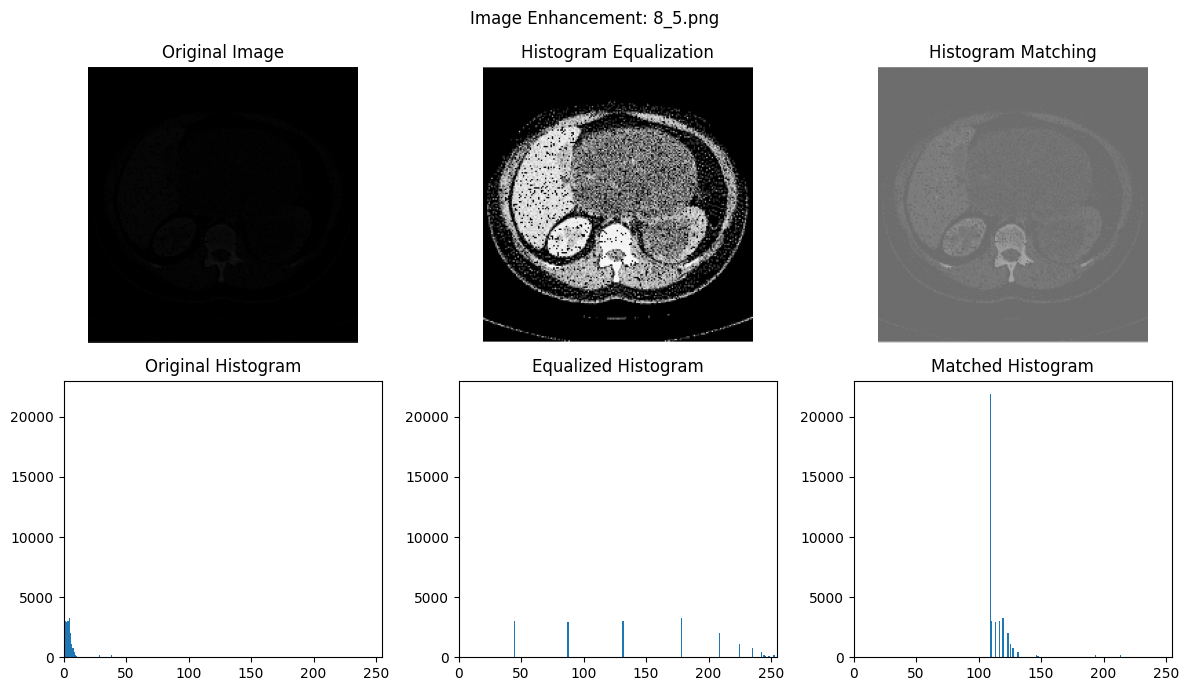

Results saved in: D:\FML\enhanced_images


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.exposure import match_histograms
from pathlib import Path

image_files = [
    "8_1.png",
    "8_2.png",
    "8_3.png",
    "8_4.png",
    "8_5.png"
]

# Output directory
output_dir = Path("enhanced_images")
output_dir.mkdir(exist_ok=True)

# Load images
images = []
for file in image_files:
    img = cv2.imread(file, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print("Could not load:", file)
        continue
    images.append((file, img))

if not images:
    raise ValueError("No images loaded. Check filenames and paths.")

# First image is the reference for histogram matching
reference_image = images[0][1]

# Process each image
for filename, original in images:
    # Histogram equalization
    equalized = cv2.equalizeHist(original)
    # Histogram matching
    matched = match_histograms(
        original,
        reference_image,
        channel_axis=None
    )
    matched = np.clip(matched, 0, 255).astype(np.uint8)

    # Save enhanced images
    cv2.imwrite(
        str(output_dir / f"equalized_{filename}"),
        equalized
    )
    cv2.imwrite(
        str(output_dir / f"matched_{filename}"),
        matched
    )

    # Create one figure with six subplots
    fig, axes = plt.subplots(2, 3, figsize=(12, 7))

    # Display images
    axes[0, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[0, 0].set_title("Original Image")
    axes[0, 0].axis("off")
    axes[0, 1].imshow(equalized, cmap="gray", vmin=0, vmax=255)
    axes[0, 1].set_title("Histogram Equalization")
    axes[0, 1].axis("off")
    axes[0, 2].imshow(matched, cmap="gray", vmin=0, vmax=255)
    axes[0, 2].set_title("Histogram Matching")
    axes[0, 2].axis("off")

    # Compare histograms
    axes[1, 0].hist(original.ravel(), bins=256, range=(0, 256))
    axes[1, 0].set_title("Original Histogram")
    axes[1, 0].set_xlim(0, 255)
    axes[1, 1].hist(equalized.ravel(), bins=256, range=(0, 256))
    axes[1, 1].set_title("Equalized Histogram")
    axes[1, 1].set_xlim(0, 255)
    axes[1, 2].hist(matched.ravel(), bins=256, range=(0, 256))
    axes[1, 2].set_title("Matched Histogram")
    axes[1, 2].set_xlim(0, 255)

    fig.suptitle(f"Image Enhancement: {filename}")
    fig.tight_layout()
    # Display and close the figure to release memory
    plt.show()
    plt.close(fig)
print("Results saved in:", output_dir.resolve())